# ` Intelligent E-Commerce Customer Analytics Platform `

#  Customer Segmentation

- Customer segmentation aims to group customers with similar purchasing behavior.
- Instead of clustering individual transactions, we use the engineered customer-level dataset created during Feature Engineering.
- Each row represents a unique customer enriched with behavioral, spending, delivery, review, and purchasing characteristics.

# Step 1 : Load Dataset

In [10]:
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Dimensionality Reduction
from sklearn.decomposition import PCA

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# ------  Load Customer Features -------------
file_path = r"C:\Users\RAaM\OneDrive\Desktop\E-Commerce Customer Analytics\data\processed\customer_features.csv"

customer_df = pd.read_csv(file_path)
print("Dataset Shape:", customer_df.shape)
customer_df.head()

Dataset Shape: (96096, 12)


,customer_unique_id,Total_Orders,Total_Spending,Average_Order_Value,Average_Basket_Size,Recency,Frequency,Monetary,Customer_Tenure,Days_Since_Last_Purchase,Average_Review_Rating,Preferred_Payment_Method
0,861eff4711a542e4b93843c6dd7febb0,1,146.87,146.87,1.0,520,1,146.87,0,520,4.0,credit_card
1,290c77bc529b7ac935b93aa66c333dc3,1,335.48,335.48,1.0,278,1,335.48,0,278,5.0,credit_card
2,060e732b5b29e8181a18229c7b0b2b5e,1,157.73,157.73,1.0,152,1,157.73,0,152,5.0,credit_card
3,259dac757896d24d7702b9acbbff3f3c,1,173.30,173.30,1.0,219,1,173.30,0,219,5.0,credit_card
4,345ecd01c38d18a9036ed96c73b8d066,1,252.25,252.25,1.0,81,1,252.25,0,81,5.0,credit_card


# Step 2 : Feature Selection

In [11]:
# Display all columns
print(customer_df.columns.tolist())

# Keep customer IDs separately
customer_ids = customer_df["customer_unique_id"].copy()

# Remove customer ID before clustering
customer_seg = customer_df.drop(columns=["customer_unique_id"]).copy()
print("Shape after removing ID:", customer_seg.shape)
customer_seg.head()



['customer_unique_id', 'Total_Orders', 'Total_Spending', 'Average_Order_Value', 'Average_Basket_Size', 'Recency', 'Frequency', 'Monetary', 'Customer_Tenure', 'Days_Since_Last_Purchase', 'Average_Review_Rating', 'Preferred_Payment_Method']
Shape after removing ID: (96096, 11)


,Total_Orders,Total_Spending,Average_Order_Value,Average_Basket_Size,Recency,Frequency,Monetary,Customer_Tenure,Days_Since_Last_Purchase,Average_Review_Rating,Preferred_Payment_Method
0,1,146.87,146.87,1.0,520,1,146.87,0,520,4.0,credit_card
1,1,335.48,335.48,1.0,278,1,335.48,0,278,5.0,credit_card
2,1,157.73,157.73,1.0,152,1,157.73,0,152,5.0,credit_card
3,1,173.30,173.30,1.0,219,1,173.30,0,219,5.0,credit_card
4,1,252.25,252.25,1.0,81,1,252.25,0,81,5.0,credit_card


In [12]:
customer_seg.info()

<class 'pandas.DataFrame'>
RangeIndex: 96096 entries, 0 to 96095
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Total_Orders              96096 non-null  int64  
 1   Total_Spending            96096 non-null  float64
 2   Average_Order_Value       96096 non-null  float64
 3   Average_Basket_Size       96096 non-null  float64
 4   Recency                   96096 non-null  int64  
 5   Frequency                 96096 non-null  int64  
 6   Monetary                  96096 non-null  float64
 7   Customer_Tenure           96096 non-null  int64  
 8   Days_Since_Last_Purchase  96096 non-null  int64  
 9   Average_Review_Rating     96096 non-null  float64
 10  Preferred_Payment_Method  96096 non-null  str    
dtypes: float64(5), int64(5), str(1)
memory usage: 9.0 MB


In [13]:
customer_seg.describe().T

,count,mean,std,min,25%,50%,75%,max
Total_Orders,96096.0,1.034809,0.214384,1.0,1.00,1.00,1.0000,17.00
Total_Spending,96096.0,214.157343,644.891987,0.0,64.00,113.34,203.4225,109312.64
Average_Order_Value,96096.0,206.066785,619.050852,0.0,63.27,111.02,196.3600,109312.64
Average_Basket_Size,96096.0,1.183750,0.718911,0.0,1.00,1.00,1.0000,38.00
Recency,96096.0,288.735691,153.414676,1.0,164.00,269.00,398.0000,773.00
Frequency,96096.0,1.034809,0.214384,1.0,1.00,1.00,1.0000,17.00
Monetary,96096.0,214.157343,644.891987,0.0,64.00,113.34,203.4225,109312.64
Customer_Tenure,96096.0,2.711507,25.393343,0.0,0.00,0.00,0.0000,633.00
Days_Since_Last_Purchase,96096.0,288.735691,153.414676,1.0,164.00,269.00,398.0000,773.00
Average_Review_Rating,96096.0,4.091516,1.339330,1.0,4.00,5.00,5.0000,5.00


# Step 3 – Data Quality Check Before Clustering

In [14]:
print("Dataset Shape:", customer_seg.shape)

# Missing values in each column
missing_values = customer_seg.isnull().sum()
print(missing_values)

# Total missing values
print("\nTotal Missing Values:", missing_values.sum())

# Total Duplicate values
duplicates = customer_seg.duplicated().sum()
print("Duplicate Rows:", duplicates)

# Check Infinite Values
numeric_df = customer_seg.select_dtypes(include=np.number)
print("\n")
print(np.isinf(numeric_df).sum())

Dataset Shape: (96096, 11)
Total_Orders                0
Total_Spending              0
Average_Order_Value         0
Average_Basket_Size         0
Recency                     0
Frequency                   0
Monetary                    0
Customer_Tenure             0
Days_Since_Last_Purchase    0
Average_Review_Rating       0
Preferred_Payment_Method    0
dtype: int64

Total Missing Values: 0
Duplicate Rows: 1240


Total_Orders                0
Total_Spending              0
Average_Order_Value         0
Average_Basket_Size         0
Recency                     0
Frequency                   0
Monetary                    0
Customer_Tenure             0
Days_Since_Last_Purchase    0
Average_Review_Rating       0
dtype: int64


In [15]:
# Duplicate customer IDs
customer_df["customer_unique_id"].duplicated().sum()


# Different customers can exhibit identical purchasing behavior. Therefore, duplicate customer identifiers should be checked before removing any rows.

np.int64(0)

# Step 4 – One-Hot Encoding (Categorical Feature)

In [16]:
# Unique payment methods
print(customer_seg["Preferred_Payment_Method"].unique())

print("\nNumber of Payment Methods:",
      customer_seg["Preferred_Payment_Method"].nunique())

<ArrowStringArray>
['credit_card', 'debit_card', 'boleto', 'voucher', 'not_defined', 'Unknown']
Length: 6, dtype: str

Number of Payment Methods: 6


In [17]:
# ======== One-Hot Encoding ===========

customer_encoded = pd.get_dummies(
    customer_seg,
    columns=["Preferred_Payment_Method"],
    drop_first=False,
    dtype=int
)

print("Shape After Encoding:", customer_encoded.shape)
customer_encoded.head()

Shape After Encoding: (96096, 16)


,Total_Orders,Total_Spending,Average_Order_Value,Average_Basket_Size,Recency,Frequency,Monetary,Customer_Tenure,Days_Since_Last_Purchase,Average_Review_Rating,Preferred_Payment_Method_Unknown,Preferred_Payment_Method_boleto,Preferred_Payment_Method_credit_card,Preferred_Payment_Method_debit_card,Preferred_Payment_Method_not_defined,Preferred_Payment_Method_voucher
0,1,146.87,146.87,1.0,520,1,146.87,0,520,4.0,0,0,1,0,0,0
1,1,335.48,335.48,1.0,278,1,335.48,0,278,5.0,0,0,1,0,0,0
2,1,157.73,157.73,1.0,152,1,157.73,0,152,5.0,0,0,1,0,0,0
3,1,173.30,173.30,1.0,219,1,173.30,0,219,5.0,0,0,1,0,0,0
4,1,252.25,252.25,1.0,81,1,252.25,0,81,5.0,0,0,1,0,0,0


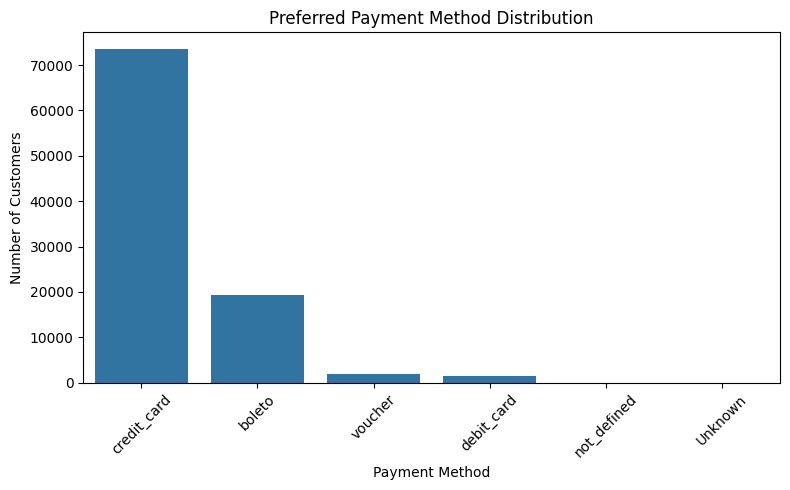

In [18]:
# ======= Visualization =======

plt.figure(figsize=(8,5))
sns.countplot(
    data=customer_seg,
    x="Preferred_Payment_Method",
    order=customer_seg["Preferred_Payment_Method"].value_counts().index
)
plt.title("Preferred Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Step 5 – Feature Scaling (StandardScaler)

In [20]:
# Initialize StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(customer_encoded)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=customer_encoded.columns,
    index=customer_encoded.index
)
print("Scaled Shape:", X_scaled.shape)


Scaled Shape: (96096, 16)


# Step 6 – Determine the Optimal Number of Clusters

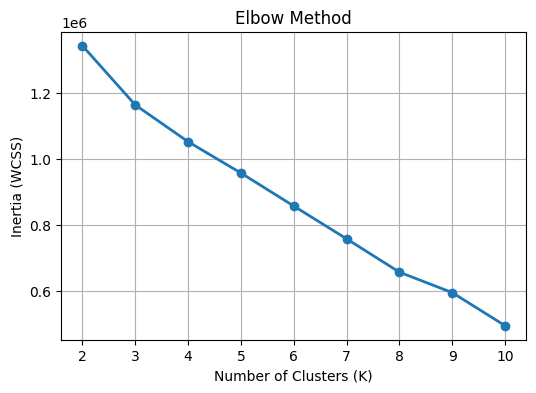

In [21]:
# ===== Elbow Method ============

inertia = []
K = range(2, 11)
for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(6,4))
plt.plot(K, inertia, marker='o', linewidth=2)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method")
plt.grid(True)
plt.show()

K = 2 | Silhouette Score = 0.4137
K = 3 | Silhouette Score = 0.4360
K = 4 | Silhouette Score = 0.3037
K = 5 | Silhouette Score = 0.3298
K = 6 | Silhouette Score = 0.3678
K = 7 | Silhouette Score = 0.3738
K = 8 | Silhouette Score = 0.3987
K = 9 | Silhouette Score = 0.4032
K = 10 | Silhouette Score = 0.4107


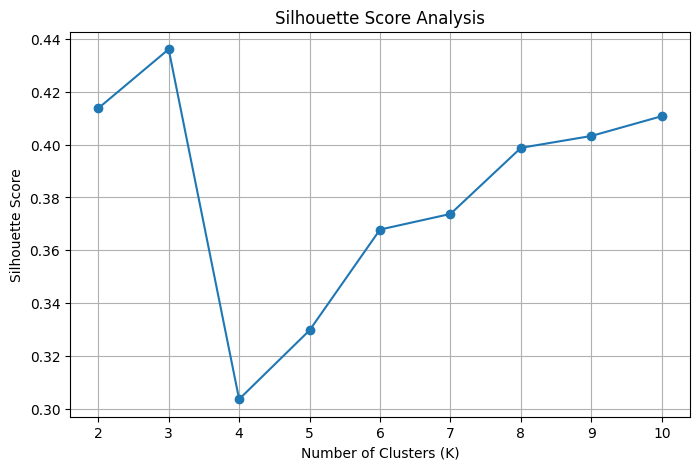

In [22]:
# =======  Silhouette Score ============


sample_size = 10000
X_sample = X_scaled.sample(
    n=sample_size,
    random_state=42
)

silhouette_scores = []
for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(X_sample)
    score = silhouette_score(X_sample, labels)
    silhouette_scores.append(score)
    print(f"K = {k} | Silhouette Score = {score:.4f}")


plt.figure(figsize=(8,5))
plt.plot(
    range(2,11),
    silhouette_scores,
    marker="o"
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Analysis")
plt.grid(True)
plt.show()

In [23]:
results = pd.DataFrame({
    "K": list(K),
    "Inertia": inertia,
    "Silhouette Score": silhouette_scores
})

results

#Interpretation:

    #The Elbow Method suggests K ≈ 3.
    #The highest Silhouette Score is also at K = 3.
    #Therefore, K = 3 is a strong candidate.

,K,Inertia,Silhouette Score
0,2,1.343657e+06,0.413663
1,3,1.164005e+06,0.436017
2,4,1.052434e+06,0.303718
3,5,9.573711e+05,0.329778
4,6,8.571673e+05,0.367849
5,7,7.576898e+05,0.373757
6,8,6.565281e+05,0.398745
7,9,5.945118e+05,0.403233
8,10,4.940992e+05,0.410715


# Step 7 – Train the Final K-Means Model

In [24]:
optimal_k = 3
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)
cluster_labels = kmeans.fit_predict(X_scaled)
clustered_customers = customer_df.copy()
clustered_customers["Cluster"] = cluster_labels
print(clustered_customers[["customer_unique_id", "Cluster"]].head())
print(clustered_customers["Cluster"].value_counts() .sort_index())

                 customer_unique_id  Cluster
0  861eff4711a542e4b93843c6dd7febb0        0
1  290c77bc529b7ac935b93aa66c333dc3        0
2  060e732b5b29e8181a18229c7b0b2b5e        0
3  259dac757896d24d7702b9acbbff3f3c        0
4  345ecd01c38d18a9036ed96c73b8d066        0
Cluster
0    71289
1    21785
2     3022
Name: count, dtype: int64


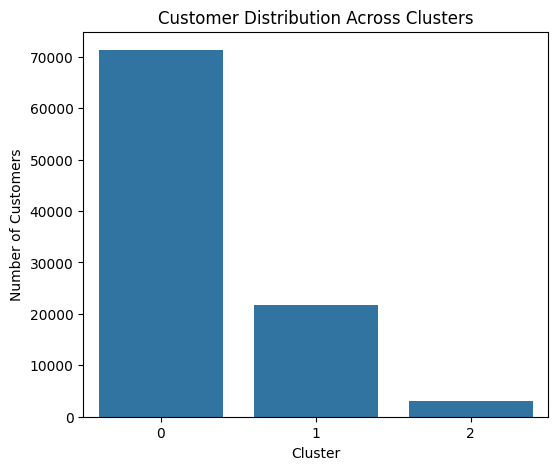

In [26]:
plt.figure(figsize=(6,5))
sns.countplot(
    data=clustered_customers,
    x="Cluster",
    order=sorted(clustered_customers["Cluster"].unique())
)
plt.title("Customer Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.show()

# Step 8 : PCA Visualization

PCA Shape: (96096, 2)


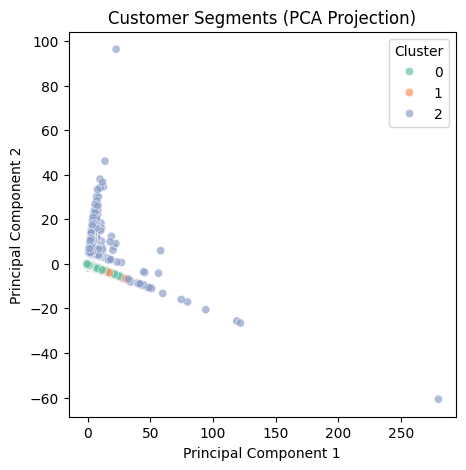

In [27]:
# Reduce dimensions
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print("PCA Shape:", X_pca.shape)

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Cluster"] = cluster_labels
pca_df.head()

plt.figure(figsize=(5,5))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    s=35,
    alpha=0.7
)
plt.title("Customer Segments (PCA Projection)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

# Step 9 – Cluster Profiling & Business Interpretation

In [28]:
cluster_profile = clustered_customers.groupby("Cluster").mean(numeric_only=True)
cluster_profile.round(2)

,Total_Orders,Total_Spending,Average_Order_Value,Average_Basket_Size,Recency,Frequency,Monetary,Customer_Tenure,Days_Since_Last_Purchase,Average_Review_Rating
Cluster,,,,,,,,,,
0,1.00,203.83,203.83,1.16,287.95,1.00,203.83,0.00,287.95,4.09
1,1.00,183.78,183.78,1.24,294.01,1.00,183.78,0.00,294.01,4.09
2,2.11,676.68,419.41,1.42,269.26,2.11,676.68,86.22,269.26,4.09


In [29]:
cluster_sizes = (
    clustered_customers["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_sizes

Cluster
0    71289
1    21785
2     3022
Name: count, dtype: int64

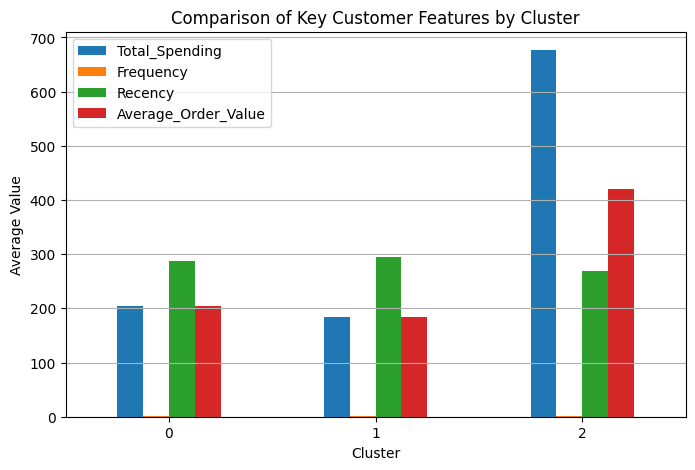

In [30]:
important_features = [
    "Total_Spending",
    "Frequency",
    "Recency",
    "Average_Order_Value"
]
cluster_profile[important_features].plot(
    kind="bar",
    figsize=(8,5)
)
plt.title("Comparison of Key Customer Features by Cluster")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

#### Interpretation
### Cluster 0 -  Regular Customers
    -These customers make moderate purchases but haven't bought very recently.
    - They are neither highest-value nor  lowest-value customers.

### Cluster 1  - Dormant Customers
    - These customers spend the least and have not purchased for the longest time.

### Cluster 2 - Premium Customers
    - These customers spend significantly more per purchase than the other groups.
    - Although they don't purchase much more frequently, they generate the highest revenue because each order is expensive.

# Step 10 : Business Segment Naming

In [31]:
segment_mapping = {
    0: "Regular Customers",
    1: "Dormant Customers",
    2: "Premium Customers"
}
clustered_customers["Customer_Segment"] = (
    clustered_customers["Cluster"]
    .map(segment_mapping)
)
segment_distribution = (
    clustered_customers["Customer_Segment"]
    .value_counts()
)

# ======== Save the Clusters ==============

cluster_profile.round(2).to_csv("../data/processed/cluster_profile.csv")
print("Cluster profile saved successfully.")



Cluster profile saved successfully.


In [32]:
customer_segments = clustered_customers[
    [
        "customer_unique_id",
        "Cluster",
        "Customer_Segment"
    ]
].copy()

customer_segments.to_csv(
    "../data/processed/customer_segments.csv",
    index=False
)
print("customer_segments.csv saved successfully.")
print("Shape:", customer_segments.shape)

customer_segments.csv saved successfully.
Shape: (96096, 3)


In [38]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\RAaM\OneDrive\Desktop\E-Commerce Customer Analytics


In [39]:
import pandas as pd
import streamlit as st
from pathlib import Path

from dashboard.utils.data_loader import load_customer_segments

segments = load_customer_segments()

print("Shape:", segments.shape)

print(
    segments.columns.tolist()
)

display(segments.head())

2026-08-08 11:46:18.146 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-08-08 11:46:18.148 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-08-08 11:46:18.150 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-08-08 11:46:18.150 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-08-08 11:46:18.151 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-08-08 11:46:18.153 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-08-08 11:46:18.153 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Shape: (96096, 3)
['customer_unique_id', 'Cluster', 'Customer_Segment']


,customer_unique_id,Cluster,Customer_Segment
0,861eff4711a542e4b93843c6dd7febb0,0,Regular Customers
1,290c77bc529b7ac935b93aa66c333dc3,0,Regular Customers
2,060e732b5b29e8181a18229c7b0b2b5e,0,Regular Customers
3,259dac757896d24d7702b9acbbff3f3c,0,Regular Customers
4,345ecd01c38d18a9036ed96c73b8d066,0,Regular Customers


In [40]:
merged_customer_test = customer_df.merge(
    segments,
    on="customer_unique_id",
    how="left"
)

print("Rows:", len(merged_customer_test))

print(
    "Missing segments:",
    merged_customer_test["Customer_Segment"]
    .isna()
    .sum()
)

Rows: 96096
Missing segments: 0
